# Check convergence 

In [7]:
import cobra
import pandas as pd
import numpy as np
import scipy
import warnings
import seaborn as sns
from collections import OrderedDict
from os import listdir
import matplotlib.pyplot as plt

from reframed.community.model import Community
from reframed import Environment, set_default_solver
from steadiercom.cli import load_communities,load_media_db

import sys
sys.path.append("../functions/")
from convergence import SteadierSampleConvergence
from convergence import std_sample_size,std_sampling_grouped,std_sampling_grouped_freq
import general

In [ ]:
import itertools

In [2]:
%load_ext autoreload
%autoreload 2

### Gut microbiome community

Concentration $X_0$ (right after serial transfer) and $X_1$ (right before next transfer) in $t_0$ and $t_1$

$$
X_1 = X_0 *e^{\mu t_1} , X_0 = X_0
$$

Assuming that the cells grow back to the original concentration (after being diluted 1:20 => the cells increase in density by 20 times)

$$
X_1/X_0 = 21 = e^{\mu t} 
$$

The above equation turns into:
$$
ln(X_1/X_0) = \mu t
$$

Which means the avearage growth rate becomes
$$
\mu_{avg} = \frac{ln(20)}{t}
$$

**Methods (From Venturelli et al. 2018): 1:20 dilution every 24 h**

In [3]:
np.log(20)/24

np.float64(0.12482217806474961)

### Select models for convergence test

In [10]:
models_gut = general.load_models_venturelli2018()

INFO     | Loading models from Venturelli et al (2018)...


**Find largest models in terms of metabolites**

In [34]:
size={}
for name, model in models_gut.items():
    size[name] = len(model.reactions)
pd.Series(size).sort_values(ascending=False).head(5)

Bacteroides_ovatus_ATCC_8483             2380
Bacteroides_uniformis_ATCC_8492          2154
Bacteroides_thetaiotaomicron_VPI_5482    2065
Bacteroides_vulgatus_ATCC_8482           1894
Faecalibacterium_prausnitzii_A2_165      1599
dtype: int64

**Find members with largest external metabolite overlap**

In [32]:
overlap={}
for name1, name2 in itertools.combinations(models_gut.keys(), 2):
    index = tuple(sorted([name1, name2]))
    ext_mets1 = models_gut[name1].get_external_metabolites()
    ext_mets2 = models_gut[name2].get_external_metabolites()
    overlap[index] = len(set(ext_mets1) & set(ext_mets2))
overlap_ser = pd.Series(overlap).sort_values(ascending=False)
overlap_ser.head(5)

Bacteroides_ovatus_ATCC_8483           Bacteroides_thetaiotaomicron_VPI_5482    471
Bacteroides_thetaiotaomicron_VPI_5482  Bacteroides_vulgatus_ATCC_8482           439
Bacteroides_ovatus_ATCC_8483           Bacteroides_uniformis_ATCC_8492          425
                                       Bacteroides_vulgatus_ATCC_8482           419
Bacteroides_thetaiotaomicron_VPI_5482  Bacteroides_uniformis_ATCC_8492          417
dtype: int64

**Make dataframe**

In [39]:
pd.DataFrame([{"community":"convergence","member":"Bacteroides_ovatus_ATCC_8483"},
              {"community":"convergence","member":"Bacteroides_thetaiotaomicron_VPI_5482"}]).to_csv("../data/Venturelli2018/generated/communities_convergence.tsv",
                                                                                                    sep="\t", 
                                                                                                    index=False,
                                                                                                    header=False)

In [42]:
mediadb = "../data/Venturelli2018/generated/media_db.tsv"#path to mediadb
medium = "LB_extend"
growth = np.log(20)/24# average growth rate

models = ["../models/Venturelli2018/species_used_noO2/"+name for name in listdir("../models/Venturelli2018/species_used_noO2/")]
communities = "../data/Venturelli2018/generated/communities_convergence.tsv"

output_dir = "../output/Venturelli2018/convergence_test_pairwise/"
comm_id="convergence"

In [59]:
%%time

abstol = 1e-6
model_cache, comm_dict, has_abundance = load_communities(models, communities, exchange_detection='R_EX_(?!biomass__40__e__41__)')

media_db, media_has_bounds = load_media_db(mediadb)
results = []

organisms = comm_dict[comm_id]

comm_models = [model_cache.get_model(org_id, reset_id=True) for org_id in organisms]
community = Community(comm_id, comm_models, copy_models=False)

env = Environment.from_reactions(media_db[medium],max_uptake=10)
env.apply(community.merged_model, inplace=False, exclusive=True, warning=False)
env_dict = dict(env)

print(f'simulating {comm_id} in {medium} medium')

sol_df = SteadierSampleConvergence(community,output_dir=output_dir,n=20001, growth=growth, allocation=True, constraints=env)

simulating convergence in LB_extend medium


/Users/idunmariaburgos/SteadierCom/reframed/reframed/solvers/gurobi_solver.py:133: UserWarning: Constrained variable 'R_EX_ala_L__91__e__93__' not previously declared
  warn(f"Constrained variable '{r_id}' not previously declared")
/Users/idunmariaburgos/SteadierCom/reframed/reframed/solvers/gurobi_solver.py:133: UserWarning: Constrained variable 'R_EX_arg_L__91__e__93__' not previously declared
  warn(f"Constrained variable '{r_id}' not previously declared")
/Users/idunmariaburgos/SteadierCom/reframed/reframed/solvers/gurobi_solver.py:133: UserWarning: Constrained variable 'R_EX_asp_L__91__e__93__' not previously declared
  warn(f"Constrained variable '{r_id}' not previously declared")
/Users/idunmariaburgos/SteadierCom/reframed/reframed/solvers/gurobi_solver.py:133: UserWarning: Constrained variable 'R_EX_cys_L__91__e__93__' not previously declared
  warn(f"Constrained variable '{r_id}' not previously declared")
/Users/idunmariaburgos/SteadierCom/reframed/reframed/solvers/gurobi_solv

Round 200. Time passed: 0.25 minutes


/Users/idunmariaburgos/SteadierCom/reframed/reframed/solvers/gurobi_solver.py:133: UserWarning: Constrained variable 'R_EX_ala_L__91__e__93__' not previously declared
  warn(f"Constrained variable '{r_id}' not previously declared")
/Users/idunmariaburgos/SteadierCom/reframed/reframed/solvers/gurobi_solver.py:133: UserWarning: Constrained variable 'R_EX_arg_L__91__e__93__' not previously declared
  warn(f"Constrained variable '{r_id}' not previously declared")
/Users/idunmariaburgos/SteadierCom/reframed/reframed/solvers/gurobi_solver.py:133: UserWarning: Constrained variable 'R_EX_asp_L__91__e__93__' not previously declared
  warn(f"Constrained variable '{r_id}' not previously declared")
/Users/idunmariaburgos/SteadierCom/reframed/reframed/solvers/gurobi_solver.py:133: UserWarning: Constrained variable 'R_EX_cys_L__91__e__93__' not previously declared
  warn(f"Constrained variable '{r_id}' not previously declared")
/Users/idunmariaburgos/SteadierCom/reframed/reframed/solvers/gurobi_solv

Round 400. Time passed: 0.25 minutes


...

Round 19600. Time passed: 0.23 minutes


/Users/idunmariaburgos/SteadierCom/reframed/reframed/solvers/gurobi_solver.py:133: UserWarning: Constrained variable 'R_EX_ala_L__91__e__93__' not previously declared
  warn(f"Constrained variable '{r_id}' not previously declared")
/Users/idunmariaburgos/SteadierCom/reframed/reframed/solvers/gurobi_solver.py:133: UserWarning: Constrained variable 'R_EX_arg_L__91__e__93__' not previously declared
  warn(f"Constrained variable '{r_id}' not previously declared")
/Users/idunmariaburgos/SteadierCom/reframed/reframed/solvers/gurobi_solver.py:133: UserWarning: Constrained variable 'R_EX_asp_L__91__e__93__' not previously declared
  warn(f"Constrained variable '{r_id}' not previously declared")
/Users/idunmariaburgos/SteadierCom/reframed/reframed/solvers/gurobi_solver.py:133: UserWarning: Constrained variable 'R_EX_cys_L__91__e__93__' not previously declared
  warn(f"Constrained variable '{r_id}' not previously declared")
/Users/idunmariaburgos/SteadierCom/reframed/reframed/solvers/gurobi_solv

Round 19800. Time passed: 0.23 minutes


/Users/idunmariaburgos/SteadierCom/reframed/reframed/solvers/gurobi_solver.py:133: UserWarning: Constrained variable 'R_EX_ala_L__91__e__93__' not previously declared
  warn(f"Constrained variable '{r_id}' not previously declared")
/Users/idunmariaburgos/SteadierCom/reframed/reframed/solvers/gurobi_solver.py:133: UserWarning: Constrained variable 'R_EX_arg_L__91__e__93__' not previously declared
  warn(f"Constrained variable '{r_id}' not previously declared")
/Users/idunmariaburgos/SteadierCom/reframed/reframed/solvers/gurobi_solver.py:133: UserWarning: Constrained variable 'R_EX_asp_L__91__e__93__' not previously declared
  warn(f"Constrained variable '{r_id}' not previously declared")
/Users/idunmariaburgos/SteadierCom/reframed/reframed/solvers/gurobi_solver.py:133: UserWarning: Constrained variable 'R_EX_cys_L__91__e__93__' not previously declared
  warn(f"Constrained variable '{r_id}' not previously declared")
/Users/idunmariaburgos/SteadierCom/reframed/reframed/solvers/gurobi_solv

Round 20000. Time passed: 0.26 minutes
CPU times: user 23min 19s, sys: 10.4 s, total: 23min 30s
Wall time: 23min 46s


In [60]:
dfs = []
for d in listdir(output_dir):
    if d.endswith(".tsv"):
        df = pd.read_csv(output_dir+str(d),sep="\t",index_col=(0,1))
        dfs.append(df)

dfs_tot = pd.concat(dfs,axis=1)
dfs_tot = dfs_tot.T.drop_duplicates().T
dfs_tot.columns = np.arange(0,dfs_tot.shape[1])

# Separate positive and degative values
pos = dfs_tot[dfs_tot>0].dropna(how="all").copy()
neg = dfs_tot[dfs_tot<0].dropna(how="all").map(abs).copy()

neg["type"]="neg"
pos["type"]="pos"
neg.set_index("type",append=True,inplace=True)
pos.set_index("type",append=True,inplace=True)

dfs_tot_abs_nan = pd.concat([pos,neg],axis=0)
dfs_tot_abs = dfs_tot_abs_nan.fillna(0)

In [61]:
dfs_tot_abs.mean().mean()

np.float64(0.0160728351946123)

### Plotting standard deviation based on sample size

The x-axis shows the number of samples in each set. The y-axis shows the standard deviation across all sets of the same size. We expect a higher number of samples in each set to cover more alternative optima and thereby reduce the variance between sets.

We see that there is lower variance between sets when their sample size is large.

In [62]:
base = 10
sample_sizes = [int(base * 2**i) for i in range(12)] 
sample_sizes = [s for s in sample_sizes if s<10000]

sample_sizes_higher_res = np.arange(1000,11000,1000)
sample_sizes_lower_res = np.arange(100,1000,100)


datas,datas_cv = std_sample_size(dfs_tot_abs,sample_sizes)
datas_higher_res,datas_higher_res_cv = std_sample_size(dfs_tot_abs,sample_sizes_higher_res)
datas_lower_res,datas_lower_res_cv = std_sample_size(dfs_tot_abs,sample_sizes_lower_res)

INFO     | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO     | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


Text(0.5, 0, 'Number of samples')

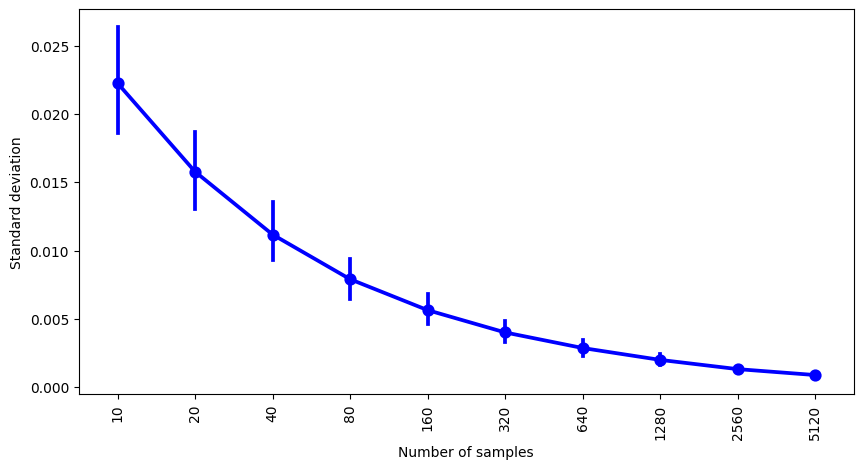

In [63]:
fig = plt.figure(figsize =(10, 5))
ax = fig.add_subplot(111)
ax = sns.pointplot(pd.DataFrame(datas),ax=ax, color="blue")
ticks = plt.xticks(rotation=90)

ax.set_ylabel("Standard deviation")
ax.set_xlabel("Number of samples")
#plt.savefig("figures_meeting/convergence_gut_noabund.png",bbox_inches="tight")

INFO     | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO     | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


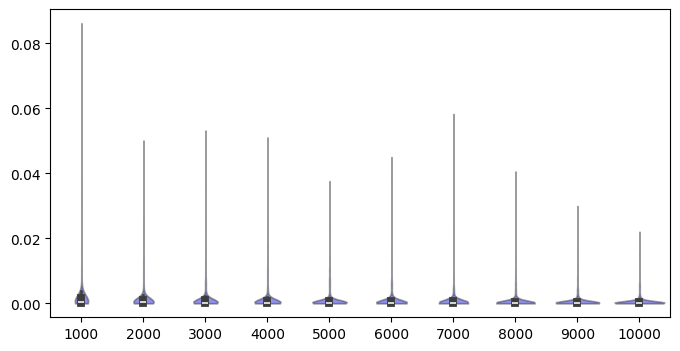

In [64]:
fig = plt.figure(figsize =(8, 4))
ax = fig.add_subplot(111)
ax = sns.violinplot(pd.DataFrame(datas_higher_res),cut=0,ax=ax,color="blue",alpha=0.5)
#ax.set_ylim([0,5e-])

INFO     | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO     | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


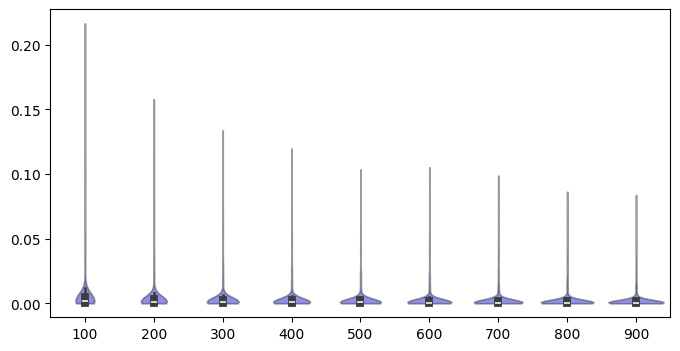

In [65]:
fig = plt.figure(figsize =(8, 4))
ax = fig.add_subplot(111)
ax = sns.violinplot(pd.DataFrame(datas_lower_res),cut=0,ax=ax,color="blue",alpha=0.5)
#ax.set_ylim([0,1e-2])

### Plotting standard deviation based on average flux rate and sample size

The x-axis represent the range of average flux rate across different sets (example: flux is between 1e-6 and 3e-6). The y-axis represents the coefficient of variance. 

We see that when the average flux is higher the coefficient of variance is lower.

In [66]:
statistics,statistics_cv = std_sampling_grouped(dfs_tot_abs,sample_sizes)

statistics_higher_res,statistics_higher_res_cv = std_sampling_grouped(dfs_tot_abs,sample_sizes_higher_res)
       

(0.0, 0.2)

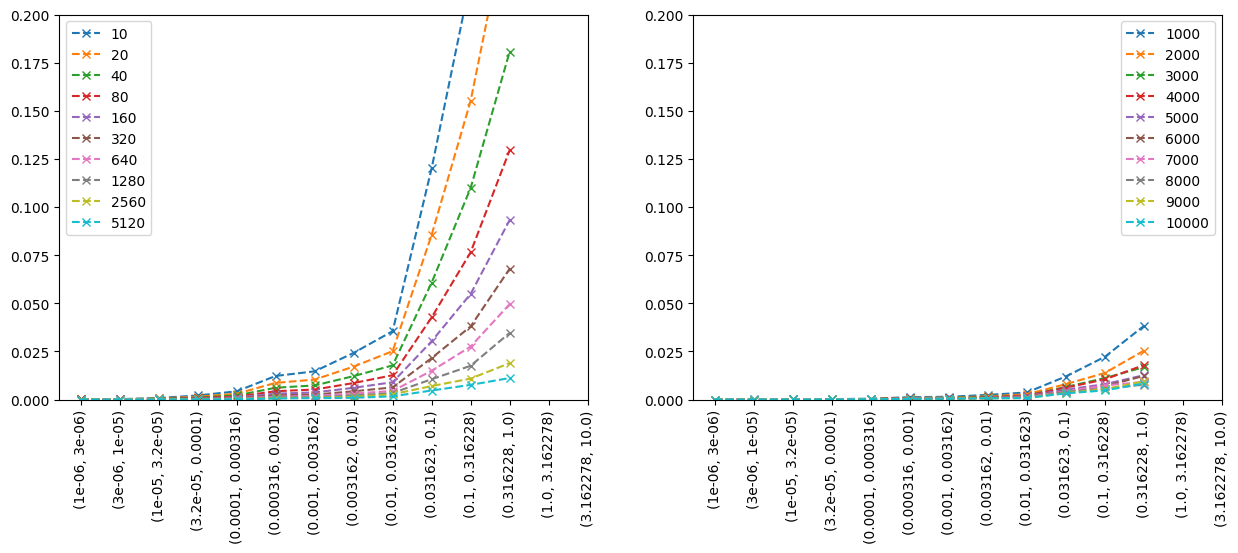

In [67]:
fig,(ax1,ax2) = plt.subplots(1,2,figsize=(15,5))

ax1 = pd.DataFrame(statistics).plot(ax=ax1,marker="x",linestyle="--")
ax1.set_xticks(np.arange(0,len(pd.DataFrame(statistics).index.values)))
ax1.set_xticklabels(pd.DataFrame(statistics).index.values,rotation=90)
ax1.legend(loc="upper left")
ax1.set_ylim([0,0.2])

ax2 = pd.DataFrame(statistics_higher_res).plot(ax=ax2,marker="x",linestyle="--")
ax2.set_xticks(np.arange(0,len(pd.DataFrame(statistics_higher_res).index.values)))
ax2.set_xticklabels(pd.DataFrame(statistics_higher_res).index.values,rotation=90)
ax2.legend(loc="upper right")
ax2.set_ylim([0,0.2])

(0.0, 100.0)

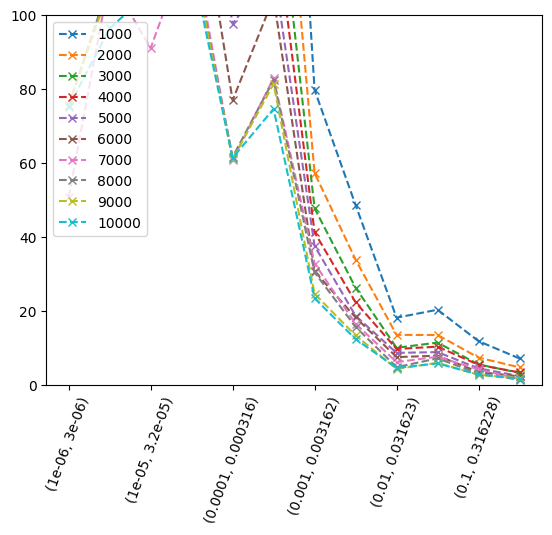

In [68]:
ax = pd.DataFrame(statistics_higher_res_cv).plot(marker="x",linestyle="--")
xticks = plt.xticks(rotation=70)
plt.legend(loc="upper left")
ax.set_ylim([0,100])

In [69]:
stats_high_res = pd.DataFrame(statistics_higher_res_cv)
diff = (stats_high_res.T.iloc[1:].reset_index(drop=True)-stats_high_res.T.iloc[:-1].reset_index(drop=True))

index = pd.Index(list(zip(np.arange(1000,10000,1000),np.arange(2000,11000,1000))))
diff.set_index(keys=index,inplace=True)

In [70]:
diff.T.mean()

1000  2000    -48.833194
2000  3000    -22.699924
3000  4000    -12.323699
4000  5000    -10.330471
5000  6000     -5.902214
6000  7000    -16.440152
7000  8000      2.599813
8000  9000     -1.204459
9000  10000    -2.049347
dtype: float64

**Sort based on frequency**

In [71]:
statistics_freq,statistics_freq_cv = std_sampling_grouped_freq(dfs_tot_abs,sample_sizes)
statistics_freq_higher_res, statistics_freq_higher_res_cv = std_sampling_grouped_freq(dfs_tot_abs,sample_sizes_higher_res)

(0.0, 0.05)

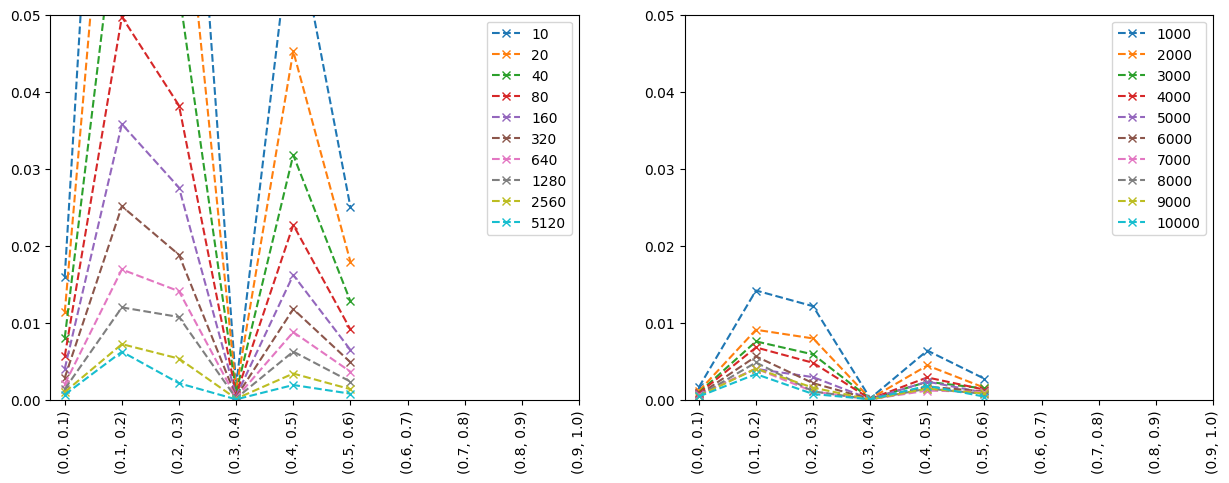

In [72]:
fig,(ax1,ax2) = plt.subplots(1,2,figsize=(15,5))
stats_df_freq = pd.DataFrame(statistics_freq)
ax1 = stats_df_freq.plot(ax=ax1,marker="x",linestyle="--")
labels =ax1.set_xticks(np.arange(len(stats_df_freq.index)))
labels = ax1.set_xticklabels(stats_df_freq.index,rotation=90)
ax1.set_ylim([0,0.05])

stats_df_freq = pd.DataFrame(statistics_freq_higher_res)
ax2 = stats_df_freq.plot(ax=ax2,marker="x",linestyle="--")
labels =ax2.set_xticks(np.arange(len(stats_df_freq.index)))
labels = ax2.set_xticklabels(stats_df_freq.index,rotation=90)
ax2.set_ylim([0,0.05])


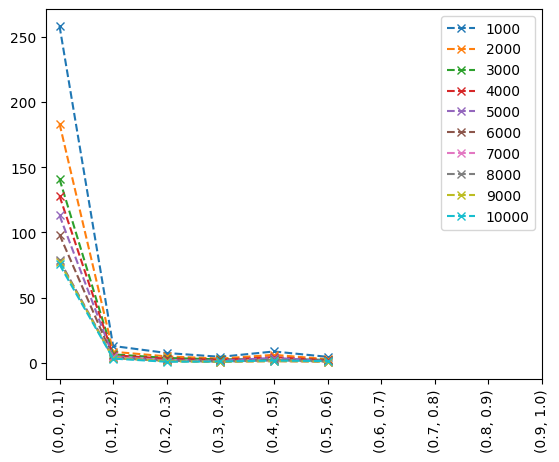

In [73]:
stats_df_freq = pd.DataFrame(statistics_freq_higher_res_cv)
ax = stats_df_freq.plot(marker="x",linestyle="--")
labels =ax.set_xticks(np.arange(len(stats_df_freq.index)))
labels = ax.set_xticklabels(stats_df_freq.index,rotation=90)

**Overview over results with filtering**

In [76]:
dfs_tot_abs

0      \
                                                                  type             
Bacteroides_ovatus_ATCC_8483          M_3meacmp__91__e__93__      pos   0.013056   
                                      M_ac__91__e__93__           pos   1.567363   
                                      M_adn__91__e__93__          pos   0.011107   
                                      M_dad_2__91__e__93__        pos   0.000000   
                                      M_for__91__e__93__          pos   1.555105   
...                                                                          ...   
                                      M_gltmn_glc__91__e__93__    neg   0.000000   
                                      M_tlf_a_m4a__91__e__93__    neg   0.000000   
                                      M_arabinoxyl__91__e__93__   neg   0.000000   
Bacteroides_thetaiotaomicron_VPI_5482 M_tpno_1glc_4g__91__e__93__ neg   0.000000   
Bacteroides_ovatus_ATCC_8483          M_7bhglzglc__91__e__93__    neg   0.000000   

                                                                        1      \
                                                                  type          
Bacteroides_ovatus_ATCC_8483          M_3meacmp__91__e__93__      pos     0.0   
                                      M_ac__91__e__93__           pos     0.0   
                                      M_adn__91__e__93__          pos     0.0   
                                      M_dad_2__91__e__93__        pos     0.0   
                                      M_for__91__e__93__          pos     0.0   
...                                                                       ...   
                                      M_gltmn_glc__91__e__93__    neg     0.0   
                                      M_tlf_a_m4a__91__e__93__    neg     0.0   
                                      M_arabinoxyl__91__e__93__   neg     0.0   
Bacteroides_thetaiotaomicron_VPI_5482 M_tpno_1glc_4g__91__e__93__ neg     0.0   
Bacteroides_ovatus_ATCC_8483          M_7bhglzglc__91__e__93__    neg     0.0   

                                                                        2      \
                                                                  type          
Bacteroides_ovatus_ATCC_8483          M_3meacmp__91__e__93__      pos     0.0   
                                      M_ac__91__e__93__           pos     0.0   
                                      M_adn__91__e__93__          pos     0.0   
                                      M_dad_2__91__e__93__        pos     0.0   
                                      M_for__91__e__93__          pos     0.0   
...                                                                       ...   
                                      M_gltmn_glc__91__e__93__    neg     0.0   
                                      M_tlf_a_m4a__91__e__93__    neg     0.0   
                                      M_arabinoxyl__91__e__93__   neg     0.0   
Bacteroides_thetaiotaomicron_VPI_5482 M_tpno_1glc_4g__91__e__93__ neg     0.0   
Bacteroides_ovatus_ATCC_8483          M_7bhglzglc__91__e__93__    neg     0.0   

                                                                        3      \
                                                                  type          
Bacteroides_ovatus_ATCC_8483          M_3meacmp__91__e__93__      pos     0.0   
                                      M_ac__91__e__93__           pos     0.0   
                                      M_adn__91__e__93__          pos     0.0   
                                      M_dad_2__91__e__93__        pos     0.0   
                                      M_for__91__e__93__          pos     0.0   
...                                                                       ...   
                                      M_gltmn_glc__91__e__93__    neg     0.0   
                                      M_tlf_a_m4a__91__e__93__    neg     0.0   
                                      M_arabinoxyl__91__e__93__ 

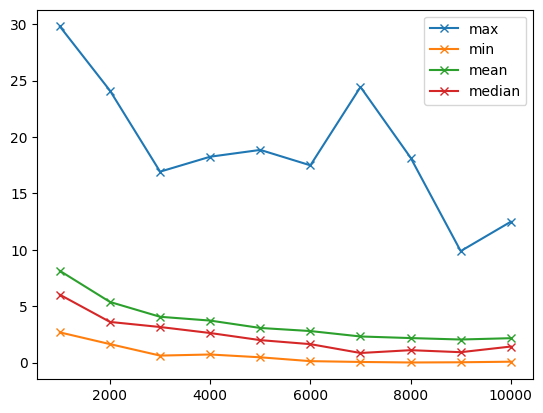

In [74]:
# For sample sizes of x calculate the frequency of the observation of values above 1e-6
sample_size=20000
data_freq = (dfs_tot_abs.T>1e-6).sum()/sample_size
index1 = data_freq>0.1

index2 = dfs_tot_abs.T.mean()>0.001
index = index1*index2
ax = pd.DataFrame(datas_higher_res_cv).loc[index].max().plot(marker='x',label="max")
ax = pd.DataFrame(datas_higher_res_cv).loc[index].min().plot(ax=ax,marker='x',label="min")
ax = pd.DataFrame(datas_higher_res_cv).loc[index].mean().plot(ax=ax,marker='x',label="mean")
ax = pd.DataFrame(datas_higher_res_cv).loc[index].median().plot(ax=ax,marker='x',label="median")
ax.legend()


In [75]:
pd.DataFrame(datas_higher_res_cv).loc[index].mean()

1000     8.132030
2000     5.373514
3000     4.060254
4000     3.723756
5000     3.068780
6000     2.795258
7000     2.314769
8000     2.173345
9000     2.045735
10000    2.162535
dtype: float64